In [ ]:
# Dane z gotowych CSV
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent
DATA = ROOT / "output"

MATCH = "match_1821123_Southampton_vs_Aston_Villa"

events = pd.read_csv(DATA / f"{MATCH}_events.csv")
players = pd.read_csv(DATA / f"{MATCH}_players.csv")
metadata = pd.read_csv(DATA / f"{MATCH}_metadata.csv")

print("events  :", events.shape)
print("players :", players.shape)
print("metadata:", metadata.shape)

# kontrola jakosci danych
print("zduplikowane wiersze :", events.duplicated().sum())
print("kolizje id           :", events["id"].duplicated().sum())


events  : (1468, 77)
players : (40, 19)
metadata: (1, 30)
zduplikowane wiersze : 0
kolizje id           : 0


In [6]:
# Szybki wybor kolumn do nowej analizy
kolumny = [
    "match_id",
    "minute",
    "expanded_minute",
    "event_type",
    "player_name",
    "x",
    "y",
]

events[kolumny].head()


,match_id,minute,expanded_minute,event_type,player_name,x,y
0,1821123,0,0,Start,NaN,0.0,0.0
1,1821123,0,0,Start,NaN,0.0,0.0
2,1821123,0,0,Pass,Marcus Rashford,50.0,50.0
3,1821123,0,0,Pass,Youri Tielemans,45.6,49.9
4,1821123,0,0,Pass,Amadou Onana,43.0,43.9


## 2. Kolumny do analizy zależności


In [8]:
import numpy as np

# identyfikatory, kategorie i duplikaty informacyjne - bez sensu w korelacjach
POMIJANE = [
    "match_id", "event_index", "id", "event_id",
    "team_id", "player_id", "related_event_id",
    "opposite_related_event_id", "next_team_id", "next_player_id",
    "receiver_id", "minute", "shirt_no", "period_value",
]

MIN_POKRYCIE = 0.5

wybrane = []
for kol in events.select_dtypes("number").columns:
    if kol in POMIJANE:
        continue
    if events[kol].notna().mean() < MIN_POKRYCIE:
        continue
    if events[kol].dropna().isin([0, 1]).all():
        continue
    wybrane.append(kol)

# usun kolumny niosace te sama informacje (|r| > 0.99)
unikalne = []
for kol in wybrane:
    for kept in unikalne:
        if abs(events[kol].corr(events[kept])) > 0.99:
            print(f"  pomijam {kol}: to samo co {kept}")
            break
    else:
        unikalne.append(kol)

wybrane = unikalne

print("\nkolumny do analizy:", len(wybrane))
for kol in wybrane:
    pokrycie = 100 * events[kol].notna().mean()
    print(f"  {kol:<26} pokrycie {pokrycie:5.1f}%")


  pomijam qualifier_pass_end_x: to samo co end_x
  pomijam qualifier_pass_end_y: to samo co end_y

kolumny do analizy: 9
  second                     pokrycie 100.0%
  expanded_minute            pokrycie 100.0%
  event_type_value           pokrycie 100.0%
  x                          pokrycie 100.0%
  y                          pokrycie 100.0%
  end_x                      pokrycie  69.3%
  end_y                      pokrycie  69.3%
  pass_length                pokrycie  69.3%
  pass_angle                 pokrycie  69.3%


## 3. Macierz korelacji


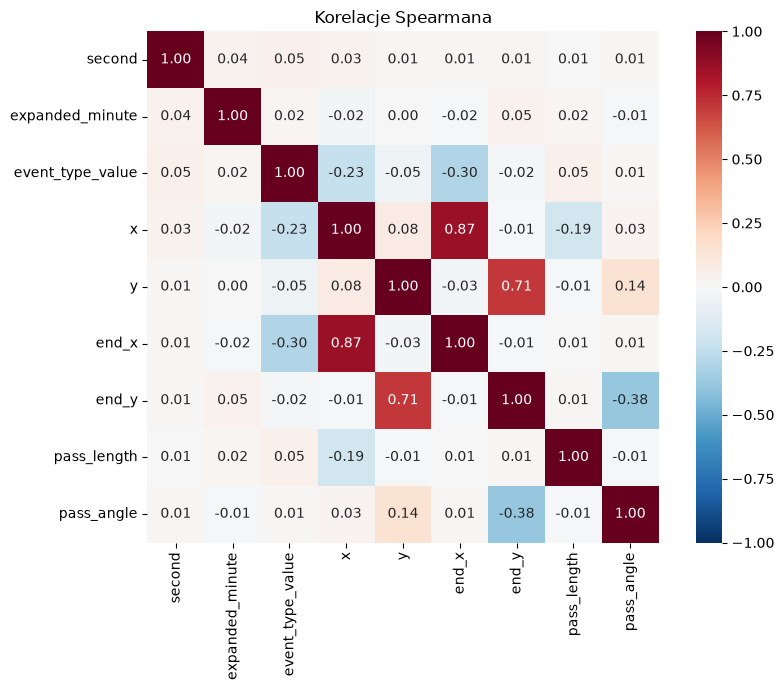

najsilniejsze pary:
  x                        <-> end_x                    r = +0.866
  y                        <-> end_y                    r = +0.711
  end_y                    <-> pass_angle               r = -0.385
  event_type_value         <-> end_x                    r = -0.301
  event_type_value         <-> x                        r = -0.232
  x                        <-> pass_length              r = -0.191
  y                        <-> pass_angle               r = +0.143
  x                        <-> y                        r = +0.081


In [9]:
import itertools

import matplotlib.pyplot as plt
import seaborn as sns

FIGURY = ROOT / "output" / "figures"
FIGURY.mkdir(parents=True, exist_ok=True)

korelacje = events[wybrane].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(korelacje, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Korelacje Spearmana")
plt.tight_layout()
plt.savefig(FIGURY / "korelacje.png", dpi=130)
plt.show()

pary = []
for a, b in itertools.combinations(wybrane, 2):
    pary.append((a, b, korelacje.loc[a, b]))
pary.sort(key=lambda t: -abs(t[2]))

print("najsilniejsze pary:")
for a, b, r in pary[:8]:
    print(f"  {a:<24} <-> {b:<24} r = {r:+.3f}")


## 4. Ranking trójek — R² płaszczyzny najmniejszych kwadratów


In [12]:
def r2_plaszczyzny(dane, x1, x2, y):
    X = np.column_stack([np.ones(len(dane)), dane[x1], dane[x2]])
    y_prawdziwe = dane[y].to_numpy()

    beta, *_ = np.linalg.lstsq(X, y_prawdziwe, rcond=None)
    y_pred = X @ beta

    ss_res = ((y_prawdziwe - y_pred) ** 2).sum()
    ss_tot = ((y_prawdziwe - y_prawdziwe.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


wyniki = []
for a, b, c in itertools.combinations(wybrane, 3):
    dane = events[[a, b, c]].dropna()
    if len(dane) < 50:
        continue

    najlepsze = (0.0, c, a, b)
    for cel in (a, b, c):
        reszta = [k for k in (a, b, c) if k != cel]
        r2 = r2_plaszczyzny(dane, reszta[0], reszta[1], cel)
        if r2 > najlepsze[0]:
            najlepsze = (r2, cel, reszta[0], reszta[1])

    wyniki.append(najlepsze)

wyniki.sort(key=lambda t: -t[0])

print(f"sprawdzono trojek: {len(wyniki)}")
print("\nTOP 10:")
for r2, cel, x1, x2 in wyniki:
    print(f"  {cel:<24} ~ {x1:<22} + {x2:<22} R2 = {r2:.4f}")


sprawdzono trojek: 84

TOP 10:
  x                        ~ end_x                  + pass_length            R2 = 0.8274
  end_y                    ~ y                      + pass_angle             R2 = 0.7718
  x                        ~ event_type_value       + end_x                  R2 = 0.7534
  x                        ~ end_x                  + pass_angle             R2 = 0.7449
  end_x                    ~ expanded_minute        + x                      R2 = 0.7445
  x                        ~ end_x                  + end_y                  R2 = 0.7443
  end_x                    ~ x                      + y                      R2 = 0.7443
  x                        ~ second                 + end_x                  R2 = 0.7441
  end_y                    ~ y                      + pass_length            R2 = 0.5025
  y                        ~ second                 + end_y                  R2 = 0.5002
  y                        ~ end_x                  + end_y                  R2

## 5. Trójki na wykresach 3D (top 4)


In [13]:
for nr, (r2, cel, x1, x2) in enumerate(wyniki[:4], start=1):
    dane = events[[x1, x2, cel]].dropna()

    X = np.column_stack([np.ones(len(dane)), dane[x1], dane[x2]])
    beta, *_ = np.linalg.lstsq(X, dane[cel].to_numpy(), rcond=None)

    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(dane[x1], dane[x2], dane[cel], s=8, alpha=0.45)

    xs = np.linspace(dane[x1].min(), dane[x1].max(), 10)
    ys = np.linspace(dane[x2].min(), dane[x2].max(), 10)
    siatka_x, siatka_y = np.meshgrid(xs, ys)
    siatka_z = beta[0] + beta[1] * siatka_x + beta[2] * siatka_y
    ax.plot_surface(siatka_x, siatka_y, siatka_z, alpha=0.3)

    ax.set_xlabel(x1)
    ax.set_ylabel(x2)
    ax.set_zlabel(cel)
    ax.set_title(f"{cel} ~ {x1} + {x2}   R2={r2:.3f}")

    plt.tight_layout()
    plt.savefig(FIGURY / f"trojka_{nr}.png", dpi=120)
    plt.close(fig)

print("wykresy zapisane w:", FIGURY)


wykresy zapisane w: c:\Users\ktskg\Desktop\Uczelnia2\SEM3\PBAD\football-match-analytics\output\figures
